# Stage 5 — Core analysis (Task 6)
**Author:** Omal Warren  |  **Project:** Comparative analysis of genetic conservation and variation in selected SARS-CoV-2 genes

Stages 1–4 define the question and clean the data. This notebook answers the question:

> **Which selected SARS-CoV-2 genes (S, E, M, N, RdRp) are most conserved across variants (Alpha, Beta, Delta, Omicron), and which show the greatest variation?**
> Hypothesis: RdRp, E and M are more conserved than Spike, especially its receptor-binding domain (RBD).

| Step | What it produces |
|---|---|
| 5.1 | A balanced, lineage-stratified set of genomes (the same genomes for every gene) |
| 5.2 | **Multiple sequence alignment** of each gene (MAFFT, called from Python) |
| 5.3 | **Conservation scores**: per-site entropy, per-gene identity to Wuhan-Hu-1, nucleotide diversity |
| 5.4 | **Mutation comparison table**: gene x variant, synonymous / non-synonymous, known mutations |
| 5.5 | **Statistical evidence**: Friedman + Wilcoxon (Holm), Fisher, Kruskal-Wallis, bootstrap CIs |

**Inputs (written by Stage 3):** `data/processed/clean_metadata.csv`, `clean_sequences.fasta`, `gene_S/E/M/N.fasta`
**Outputs:** `results/alignments/`, `results/stage5_*.csv`, `results/figures/fig6*.png`

> The RdRp gene is not in Stage 3's gene files (Stage 3 extracted the whole ORF1ab), so this notebook cuts RdRp (nsp12) out itself in 5.1.

In [ ]:
%pip install -q biopython mappy pandas numpy matplotlib seaborn scipy statsmodels

In [ ]:
from pathlib import Path
import os, subprocess, shutil

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    colab_root = Path("/content/bioinformatics-group-project")
    if not colab_root.exists():
        subprocess.run(["git", "clone", "https://github.com/JudahNdivo/bioinformatics-group-project.git",
                        str(colab_root)], check=True)
    os.chdir(colab_root)

cwd = Path.cwd()
if (cwd / "data").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Could not find the project's data/ folder.")

DATA_DIR = PROJECT_ROOT / "data"
OUT_DIR  = DATA_DIR / "processed"
RES_DIR  = PROJECT_ROOT / "results"
FIG_DIR  = RES_DIR / "figures"
ALN_DIR  = RES_DIR / "alignments"
for d in (FIG_DIR, ALN_DIR):
    d.mkdir(parents=True, exist_ok=True)

needed = ["clean_metadata.csv", "clean_sequences.fasta", "gene_S.fasta", "gene_E.fasta", "gene_M.fasta", "gene_N.fasta"]
missing = [f for f in needed if not (OUT_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing Stage 3 outputs {missing}. Run the Stage 3 cells first "
                            "(data/processed/ is not stored on GitHub).")

# MAFFT is a command-line aligner; we call it from Python. Colab can install it with apt.
def ensure_mafft():
    if shutil.which("mafft"):
        return
    if IN_COLAB:
        subprocess.run(["apt-get", "update", "-qq"], check=False)
        subprocess.run(["apt-get", "install", "-y", "-qq", "mafft"], check=True)
    else:
        raise RuntimeError("MAFFT not found. Install it (macOS: brew install mafft; Ubuntu: apt install mafft) or run in Colab.")
ensure_mafft()
print("Environment :", "Google Colab" if IN_COLAB else "Local")
print("MAFFT       :", subprocess.run(["mafft", "--version"], capture_output=True, text=True).stderr.strip())

Environment :

 Local
MAFFT       : v7.505 (2022/Apr/10)


In [ ]:
import numpy as np, pandas as pd, mappy as mp
import matplotlib.pyplot as plt, seaborn as sns
from itertools import combinations
from scipy import stats
from statsmodels.stats.multitest import multipletests
from Bio import SeqIO, AlignIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200})

# ---- choices the group can change (re-run the notebook afterwards) ----
SEED          = 42
N_PER_VARIANT = 25          # target genomes per variant (minutes: 20-30)
VARIANTS      = ["Alpha", "Beta", "Delta", "Omicron"]
MIN_MINOR     = 2           # a site is 'variable' if the minority state occurs in >= 2 genomes (ignores singleton errors)
N_BOOT        = 1000        # bootstrap replicates
RBD_AA        = (319, 541)  # Spike receptor-binding domain, amino-acid positions

# Gene coordinates on NC_045512.2 (1-based, inclusive). RdRp = nsp12, which is made with a -1 ribosomal frameshift at nt 13468.
GENE_ORDER = ["S", "E", "M", "N", "RdRp"]
COORDS = {"S": (21563, 25384), "E": (26245, 26472), "M": (26523, 27191), "N": (28274, 29533), "RdRp": (13442, 16236)}
SLIP_1BASED = 13468

ref_rec = SeqIO.read(DATA_DIR / "wuhan_reference.fasta", "fasta")
ref_seq = str(ref_rec.seq).upper()
def ref_gene(g):
    a, b = COORDS[g]
    s = ref_seq[a - 1:b]
    if g == "RdRp":                      # repeat the slippery nucleotide to restore the reading frame
        k = SLIP_1BASED - a              # index of the slip nt inside the region
        s = s[:k + 1] + s[k:]
    return s
REF = {g: ref_gene(g) for g in GENE_ORDER}

# Sanity check: each gene must be a clean ORF (multiple of 3, starts ATG, ends with stop, no internal stop)
for g in GENE_ORDER:
    p = str(Seq(REF[g]).translate())
    print(f"{g:5s} {len(REF[g]):5d} nt  {len(REF[g])//3 - 1:5d} aa  starts {p[:7]}  internal stops: {p[:-1].count('*')}")
    assert len(REF[g]) % 3 == 0 and p[:-1].count("*") == 0

S      3822 nt   1273 aa  starts MFVFLVL  internal stops: 0
E       228 nt     75 aa  starts MYSFVSE  internal stops: 0
M       669 nt    222 aa  starts MADSNGT  internal stops: 0
N      1260 nt    419 aa  starts MSDNGPQ  internal stops: 0
RdRp   2796 nt    931 aa  starts SADAQSF  internal stops: 0


### 5.1 Choose the genomes and extract RdRp
**Why not use all 2,811 genomes?** The minutes agreed on about 20-30 genomes per variant, which keeps alignments fast and the comparison balanced. The cleaned data are very unbalanced (Stage 4, Figure 2), and many genomes are near-identical copies of one lineage, so a random draw would mostly sample two or three Omicron lineages. Instead we draw **round-robin across Pango lineages** inside each variant, so each variant is represented by as many different lineages as possible.

Two further rules: every selected genome must have a complete copy of **all five genes** (so every gene is measured on the same genomes, which the paired tests in 5.5 need), and RdRp must be extracted first because Stage 3 only saved ORF1ab.

In [ ]:
meta = pd.read_csv(OUT_DIR / "clean_metadata.csv", low_memory=False)
gene_idx = {g: SeqIO.index(str(OUT_DIR / f"gene_{g}.fasta"), "fasta") for g in ["S", "E", "M", "N"]}
ids_core = set.intersection(*[set(gene_idx[g].keys()) for g in gene_idx])
cand = meta[meta["clade_who"].isin(VARIANTS) & meta["strain"].isin(ids_core)].copy()
print("Candidates with S, E, M and N complete, by variant:")
print(cand["clade_who"].value_counts().reindex(VARIANTS).to_string())

# ---- extract RdRp (nsp12) from the cleaned genomes, using the same minimap2 mapping idea as Stage 3 ----
aligner = mp.Aligner(seq=ref_seq, preset="asm5")
REF_LEN = len(ref_seq)

def ref_to_query(hits):
    r2q = np.full(REF_LEN, -1, dtype=np.int64)
    for h in hits:
        r, q = h.r_st, h.q_st
        for length, op in h.cigar:
            if op in (0, 7, 8):
                r2q[r:r + length] = np.arange(q, q + length); r += length; q += length
            elif op == 1:
                q += length
            elif op in (2, 3):
                r += length
    return r2q

def extract_rdrp(s):
    a, b = COORDS["RdRp"][0] - 1, COORDS["RdRp"][1]
    hits = [h for h in aligner.map(s) if h.strand == 1]
    if not hits:
        return None
    r2q = ref_to_query(hits)
    mapped = r2q[a:b][r2q[a:b] >= 0]
    q_slip = r2q[SLIP_1BASED - 1]
    if len(mapped) / (b - a) < 0.95 or q_slip < 0:
        return None
    seg = s[mapped[0]: q_slip + 1] + s[q_slip: mapped[-1] + 1]          # frameshift-corrected coding sequence
    if 1 - sum(seg.count(x) for x in "ACGT") / len(seg) > 0.01:
        return None
    if len(seg) % 3 != 0 or "*" in str(Seq(seg).translate())[:-1]:
        return None
    return seg

genomes = SeqIO.index(str(OUT_DIR / "clean_sequences.fasta"), "fasta")
rdrp = {}
for sid in cand["strain"]:
    seg = extract_rdrp(str(genomes[sid].seq).upper())
    if seg:
        rdrp[sid] = seg
cand = cand[cand["strain"].isin(rdrp)]
print(f"\nRdRp extracted for {len(rdrp)} genomes; candidates with all five genes: {len(cand)}")

Candidates with S, E, M and N complete, by variant:
clade_who
Alpha       33
Beta         4
Delta       85
Omicron    450



RdRp extracted for 568 genomes; candidates with all five genes: 568


In [ ]:
def stratified_sample(df, n, seed):
    # Round-robin over Pango lineages (random order) so one big lineage cannot dominate the sample
    rng = np.random.default_rng(seed)
    groups = {str(k): list(rng.permutation(v["strain"].values)) for k, v in df.groupby("pango_lineage")}
    order = [str(x) for x in rng.permutation(list(groups))]
    picked = []
    while len(picked) < n and any(groups.values()):
        for k in order:
            if groups[k] and len(picked) < n:
                picked.append(groups[k].pop())
    return picked

parts = []
for v in VARIANTS:
    sub = cand[cand["clade_who"] == v]
    ids = stratified_sample(sub, N_PER_VARIANT, SEED)
    parts.append(sub[sub["strain"].isin(ids)])
sel = pd.concat(parts)[["strain", "clade_who", "pango_lineage", "country", "date"]].rename(columns={"clade_who": "variant"})
sel["variant"] = pd.Categorical(sel["variant"], VARIANTS, ordered=True)
sel = sel.sort_values(["variant", "pango_lineage", "strain"]).reset_index(drop=True)
sel["seq_id"] = [f"g{i:03d}" for i in range(len(sel))]       # safe short IDs for the aligner
sel.to_csv(RES_DIR / "stage5_selected_genomes.csv", index=False)

summary = sel.groupby("variant", observed=True).agg(genomes=("strain", "size"), lineages=("pango_lineage", "nunique"),
                                                    countries=("country", "nunique"))
summary["available_after_QC"] = cand["clade_who"].value_counts().reindex(VARIANTS).values
display(summary)
print(f"Total selected: {len(sel)} genomes (+ Wuhan-Hu-1 reference in every alignment)")

,genomes,lineages,countries,available_after_QC
variant,,,,
Alpha,25,1,21,32
Beta,4,2,3,4
Delta,25,25,16,85
Omicron,25,25,12,447


Total selected: 79 genomes (+ Wuhan-Hu-1 reference in every alignment)


**Interpretation 5.1:**
The final sample has 79 genomes plus the Wuhan-Hu-1 reference: 25 Alpha, 25 Delta, 25 Omicron and 4 Beta. Alpha, Delta and Omicron reached the target of 25 genomes. Beta has only 4 genomes (2 lineages, 3 countries). Seven Beta genomes passed Stage 3, but only 4 had complete copies of all five genes, so every Beta-specific result is weak and is reported with that caution. Alpha is a single lineage (B.1.1.7) from 21 countries. Delta and Omicron each draw 25 different lineages from 16 and 12 countries, so they represent the variation inside each variant better. The group should decide whether to download more Beta genomes from NCBI Virus or to report the small sample as a limitation.

### 5.2 Multiple sequence alignment
For each gene, the reference and the selected genomes are written to a FASTA file and aligned with **MAFFT** (`--auto`), called from Python. MAFFT is a standard aligner and fast enough for about 100 sequences of 0.2-4 kb. The alignment is then loaded back with Biopython. Web tools (Clustal Omega, NCBI BLAST) are only needed for the cross-check agreed in the minutes: paste one gene's `unaligned_<gene>.fasta` into Clustal Omega and compare the variable sites.

Two checks follow: removing the gaps from the reference row must give back the original reference gene, and every sequence must have the expected length (plus or minus any real indel).

In [ ]:
GENE_SEQS = {g: {sid: str(gene_idx[g][sid].seq).upper() for sid in sel["strain"]} for g in ["S", "E", "M", "N"]}
GENE_SEQS["RdRp"] = {sid: rdrp[sid] for sid in sel["strain"]}

def run_mafft(g):
    recs = [SeqRecord(Seq(REF[g]), id="REF", description="")]
    recs += [SeqRecord(Seq(GENE_SEQS[g][r.strain]), id=r.seq_id, description="") for r in sel.itertuples()]
    inp, out = ALN_DIR / f"unaligned_{g}.fasta", ALN_DIR / f"aln_{g}.fasta"
    SeqIO.write(recs, inp, "fasta")
    with open(out, "w") as fh:
        subprocess.run(["mafft", "--auto", "--quiet", "--thread", "-1", str(inp)], stdout=fh,
                       stderr=subprocess.DEVNULL, check=True)
    return AlignIO.read(out, "fasta")

ORDER = ["REF"] + list(sel["seq_id"])
LUT = np.full(256, 5, dtype=np.uint8)                  # 0-3 = A,C,G,T   4 = gap   5 = N / ambiguous (treated as missing)
for i, ch in enumerate(b"ACGT-"):
    LUT[ch] = i

aln_rows = []
STATES = {}                                            # gene -> (n+1, L_ref) matrix, columns = reference positions
INSERTS = {}
for g in GENE_ORDER:
    aln = run_mafft(g)
    d = {r.id: str(r.seq).upper() for r in aln}
    assert "".join(d["REF"].split("-")) == REF[g], f"{g}: reference changed during alignment"
    full = np.vstack([LUT[np.frombuffer(d[i].encode(), dtype=np.uint8)] for i in ORDER])
    keep = full[0] != 4                                # columns where the reference has a base
    STATES[g] = full[:, keep]
    INSERTS[g] = (full[1:, ~keep] != 4).sum(axis=1)    # bases that sit in reference gaps (insertions)
    aln_rows.append({"gene": g, "sequences": len(d), "alignment_length": aln.get_alignment_length(),
                     "reference_length": len(REF[g]), "extra_columns_(insertions)": int((~keep).sum()),
                     "genomes_with_insertion": int((INSERTS[g] > 0).sum())})
aln_summary = pd.DataFrame(aln_rows).set_index("gene")
display(aln_summary)
aln_summary.to_csv(RES_DIR / "stage5_alignment_summary.csv")
print("Alignments saved in", ALN_DIR)

,sequences,alignment_length,reference_length,extra_columns_(insertions),genomes_with_insertion
gene,,,,,
S,80,3822,3822,0,0
E,80,228,228,0,0
M,80,669,669,0,0
N,80,1260,1260,0,0
RdRp,80,2796,2796,0,0


Alignments saved in ./results/alignments


**Interpretation 5.2 :MAFFT aligned all five genes. In every gene the alignment length equals the reference length (S 3,822, E 228, M 669, N 1,260, RdRp 2,796 nt), and no genome has an insertion. Gaps therefore mark deletions only. The most common ones are in Spike: the H69 deletion in 92% of Alpha genomes, F157 in 88% of Delta genomes, and P25–P26 in 68% of Omicron genomes. In N, E31–R32 is deleted in 72% of Omicron genomes. These match deletions reported in the literature. The exact codon labels can shift by one residue depending on where the aligner places a gap.

### 5.3 Conservation scores
All scores below ignore `N` / ambiguous calls (missing data) and count a gap as a fifth state (a deletion is a real difference). Columns are indexed by **reference position**, so site 1 of S is the first base of the S gene in Wuhan-Hu-1.

| Score | Meaning |
|---|---|
| **Shannon entropy** *H* (bits) per site | 0 = every genome has the same base; higher = more variable |
| **Conservation** = 1 - *H* / log2(5) | 1 = perfectly conserved site |
| **Variable site** | minority state seen in >= `MIN_MINOR` genomes (a site seen differing once may be a sequencing error) |
| **Nucleotide diversity** *pi* | mean number of differences per site between two random genomes |
| **Identity to Wuhan-Hu-1** (per genome) | % of comparable positions that match the reference (a gap counts as a difference, `N` is skipped) |

Per-genome identity is the main measure used for statistics in 5.5 because it gives one number per genome and gene.

In [ ]:
def site_stats(X):
    # X: (n, L) states 0-4 valid, 5 missing
    counts = np.stack([(X == k).sum(axis=0) for k in range(5)])
    nvalid = counts.sum(axis=0)
    p = counts / np.maximum(nvalid, 1)
    H = -np.where(p > 0, p * np.log2(np.where(p > 0, p, 1)), 0).sum(axis=0)
    pi = np.where(nvalid > 1, nvalid / np.maximum(nvalid - 1, 1) * (1 - (p ** 2).sum(axis=0)), 0.0)
    minor = nvalid - counts.max(axis=0)
    return {"counts": counts, "nvalid": nvalid, "H": H, "pi": pi, "minor": minor}

SITE = {g: site_stats(STATES[g][1:]) for g in GENE_ORDER}
var_arr = sel["variant"].astype(str).values

# ---- per-gene summary ----
rows = []
for g in GENE_ORDER:
    s = SITE[g]; L = STATES[g].shape[1]
    variable = int((s["minor"] >= MIN_MINOR).sum())
    rows.append({"gene": g, "length_nt": L, "variable_sites": variable,
                 "variable_sites_per_kb": round(1000 * variable / L, 1),
                 "pct_invariant_sites": round(100 * (s["minor"] == 0).mean(), 1),
                 "mean_entropy_bits": round(s["H"].mean(), 4),
                 "mean_conservation": round((1 - s["H"] / np.log2(5)).mean(), 4),
                 "nucleotide_diversity_pi": round(s["pi"].mean(), 5)})
gene_cons = pd.DataFrame(rows).set_index("gene")
display(gene_cons)
gene_cons.to_csv(RES_DIR / "stage5_gene_conservation.csv")

# ---- per-genome identity to Wuhan-Hu-1 (one row per genome x gene) ----
recs = []
for g in GENE_ORDER:
    ref, Q = STATES[g][0], STATES[g][1:]
    comparable = Q != 5
    diff = comparable & (Q != ref)
    d, c = diff.sum(axis=1), comparable.sum(axis=1)
    recs.append(pd.DataFrame({"strain": sel["strain"].values, "variant": var_arr, "gene": g, "diffs": d, "compared": c,
                              "density_per_kb": 1000 * d / c, "identity_pct": 100 * (1 - d / c)}))
dens = pd.concat(recs, ignore_index=True)
dens["gene"] = pd.Categorical(dens["gene"], GENE_ORDER, ordered=True)
dens.to_csv(RES_DIR / "stage5_genome_identity.csv", index=False)

ident = dens.pivot_table(index="gene", columns="variant", values="identity_pct", aggfunc="mean", observed=True)[VARIANTS].round(3)
print("Mean % identity to Wuhan-Hu-1, by gene and variant:")
display(ident)

,length_nt,variable_sites,variable_sites_per_kb,pct_invariant_sites,mean_entropy_bits,mean_conservation,nucleotide_diversity_pi
gene,,,,,,,
S,3822,132,34.5,94.2,0.0246,0.9894,0.01032
E,228,4,17.5,96.5,0.0083,0.9964,0.00314
M,669,12,17.9,97.3,0.0113,0.9951,0.00473
N,1260,27,21.4,95.7,0.0180,0.9923,0.00787
RdRp,2796,13,4.6,98.6,0.0034,0.9985,0.00136


Mean % identity to Wuhan-Hu-1, by gene and variant:


variant,Alpha,Beta,Delta,Omicron
gene,,,,
S,99.587,99.634,99.640,98.472
E,99.982,99.342,99.982,99.526
M,99.982,99.925,99.821,99.259
N,99.416,99.881,99.686,98.993
RdRp,99.827,99.946,99.907,99.888


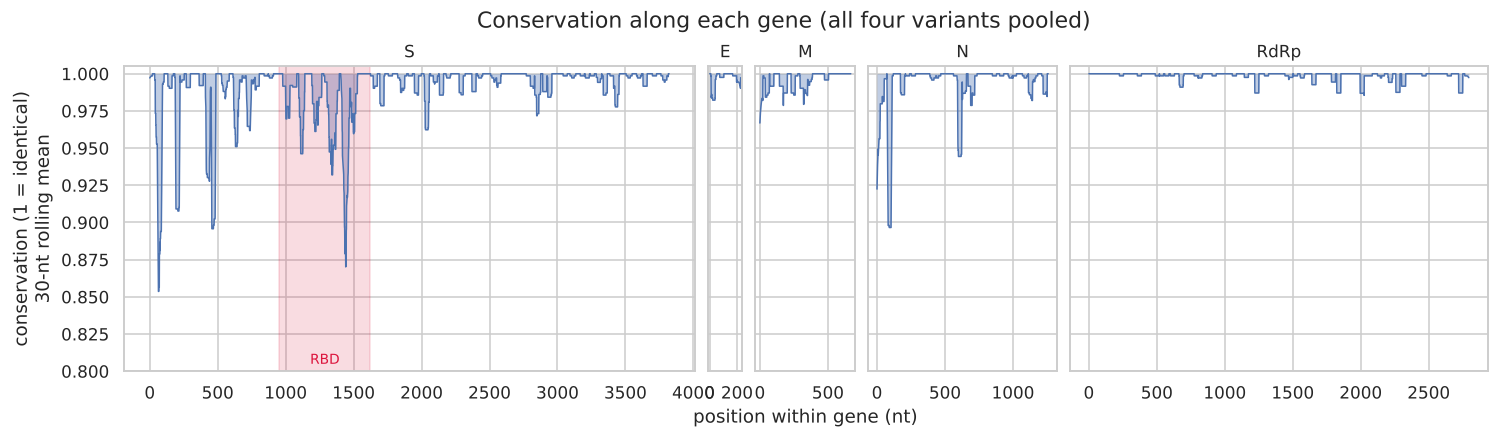

In [ ]:
# ---- Figure 6a: conservation profile along each gene (rolling mean of per-site conservation) ----
lengths = [STATES[g].shape[1] for g in GENE_ORDER]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharey=True, gridspec_kw={"width_ratios": lengths, "wspace": 0.05})
for ax, g in zip(axes, GENE_ORDER):
    cons = 1 - SITE[g]["H"] / np.log2(5)
    roll = pd.Series(cons).rolling(30, center=True, min_periods=1).mean()
    ax.fill_between(np.arange(len(cons)), roll, 1, color="#4C72B0", alpha=0.35, lw=0)
    ax.plot(roll.values, color="#4C72B0", lw=1)
    ax.set_title(g, fontsize=11); ax.set_xlabel("")
    if g == "S":
        a, b = 3 * (RBD_AA[0] - 1), 3 * RBD_AA[1]
        ax.axvspan(a, b, color="crimson", alpha=0.15); ax.text((a + b) / 2, 0.805, "RBD", ha="center", color="crimson", fontsize=9)
axes[0].set_ylabel("conservation (1 = identical)\n30-nt rolling mean"); axes[0].set_ylim(0.8, 1.005)
axes[2].set_xlabel("position within gene (nt)")
fig.suptitle("Conservation along each gene (all four variants pooled)", y=1.02)
plt.savefig(FIG_DIR / "fig6a_conservation_profile.png", bbox_inches="tight"); plt.show()

**Interpretation 5.3 :
Ranked by variable sites per kb, Spike is the most variable gene (132 sites, 34.5/kb), followed by N (21.4), M (17.9), E (17.5) and RdRp (4.6). Nucleotide diversity gives the same ranking as variable sites per kb: Spike 0.0103, N 0.0079, M 0.0047, E 0.0031, RdRp 0.0014. RdRp is the most conserved gene, with 98.6% of its sites invariant, against 94.2% for Spike. Omicron is the most divergent variant from Wuhan-Hu-1 in Spike (98.47% identity, against about 99.6% for the others). RdRp stays at 99.8% identity or higher in all four variants. In Figure 6a the largest dips in Spike lie in the N-terminal region and in the RBD, with smaller dips elsewhere, while RdRp stays almost flat. The hypothesis is therefore supported for RdRp. It is only partly supported for E and M, which are less variable than Spike but not by a large margin. E has only 4 variable sites in 228 nt, so its rate is imprecise. These values describe this balanced sample, not the whole virus population.

### 5.4 Mutation comparison table
We turn the alignment into amino-acid changes by comparing each genome's codons with the reference's codons. A codon with an `N` is skipped; a codon fully missing in the genome is recorded as a deletion; a change that alters the amino acid is **non-synonymous (NS)** and one that does not is **synonymous (S)**.

Two views are produced:
1. A **gene x variant table** from each variant's *consensus* (most common base at every site), which shows the changes that define each variant relative to Wuhan-Hu-1.
2. A **known-mutation check** (D614G, N501Y, E484K and others named in the minutes and the literature) giving the share of genomes in each variant that carry them. It doubles as a pipeline test: if D614G is missing from almost all post-2020 genomes, something is wrong.

In [ ]:
AA = np.array([str(Seq("ACGT"[i // 16] + "ACGT"[i // 4 % 4] + "ACGT"[i % 4]).translate()) for i in range(64)])

def codon_arrays(M):
    m, L = M.shape; k = L // 3
    T = M[:, :k * 3].reshape(m, k, 3).astype(np.int16)
    valid = (T < 4).all(axis=2)
    idx = np.where(valid, T[..., 0] * 16 + T[..., 1] * 4 + T[..., 2], -1)
    allgap = (T == 4).all(axis=2)
    return idx, allgap

def codon_events(M):
    # M[0] = reference. Returns one row per (genome, codon) that differs from the reference.
    idx, allgap = codon_arrays(M)
    r = idx[0]
    out = []
    ch = (idx[1:] >= 0) & (idx[1:] != r)
    i, j = np.where(ch)
    ra, aa_ = AA[r[j]], AA[idx[1:][i, j]]
    out.append(pd.DataFrame({"row": i, "codon": j + 1, "ref_aa": ra, "alt_aa": aa_,
                             "kind": np.where(ra == aa_, "synonymous", "non-synonymous")}))
    i, j = np.where(allgap[1:])
    out.append(pd.DataFrame({"row": i, "codon": j + 1, "ref_aa": AA[r[j]], "alt_aa": "-", "kind": "deletion"}))
    ev = pd.concat(out, ignore_index=True)
    ev["label"] = np.where(ev["kind"] == "deletion", "del" + ev["ref_aa"] + ev["codon"].astype(str),
                           ev["ref_aa"] + ev["codon"].astype(str) + ev["alt_aa"])
    return ev, idx

EV, CIDX = {}, {}
for g in GENE_ORDER:
    ev, idx = codon_events(STATES[g])
    ev["gene"] = g; ev["strain"] = sel["strain"].values[ev["row"]]; ev["variant"] = var_arr[ev["row"]]
    EV[g], CIDX[g] = ev, idx
events = pd.concat(EV.values(), ignore_index=True)
events.drop(columns="row").to_csv(RES_DIR / "stage5_codon_changes_per_genome.csv", index=False)
print(f"{len(events):,} codon-level differences from Wuhan-Hu-1 across {len(sel)} genomes and 5 genes")

# ---- (1) gene x variant table from each variant's consensus ----
rows = []
for g in GENE_ORDER:
    X, L = STATES[g], STATES[g].shape[1]
    cons_rows = []
    for v in VARIANTS:
        c = site_stats(X[1:][var_arr == v])["counts"]
        cons = np.where(c.sum(axis=0) > 0, c.argmax(axis=0), 5).astype(np.uint8)
        cons_rows.append(cons)
    ev_c, _ = codon_events(np.vstack([X[0]] + cons_rows))
    for k, v in enumerate(VARIANTS):
        cons = cons_rows[k]
        sub = int(((cons < 4) & (cons != X[0])).sum())
        e = ev_c[ev_c["row"] == k]
        rows.append({"gene": g, "variant": v, "length_nt": L, "nt_substitutions": sub, "substitutions_per_kb": round(1000 * sub / L, 2),
                     "nt_deleted_sites": int((cons == 4).sum()), "aa_changes_(NS)": int((e["kind"] == "non-synonymous").sum()),
                     "synonymous": int((e["kind"] == "synonymous").sum()), "aa_deletions": int((e["kind"] == "deletion").sum())})
mut_table = pd.DataFrame(rows)
mut_table.to_csv(RES_DIR / "stage5_mutation_table.csv", index=False)
display(mut_table.set_index(["gene", "variant"]))

2,418 codon-level differences from Wuhan-Hu-1 across 79 genomes and 5 genes


length_nt  nt_substitutions  substitutions_per_kb  \
gene variant                                                      
S    Alpha         3822                 7                  1.83   
     Beta          3822                 8                  2.09   
     Delta         3822                 7                  1.83   
     Omicron       3822                33                  8.63   
E    Alpha          228                 0                  0.00   
     Beta           228                 1                  4.39   
     Delta          228                 0                  0.00   
     Omicron        228                 1                  4.39   
M    Alpha          669                 0                  0.00   
     Beta           669                 0                  0.00   
     Delta          669                 1                  1.49   
     Omicron        669                 4                  5.98   
N    Alpha         1260                 7                  5.56   
     Beta          1260                 1                  0.79   
     Delta         1260                 4                  3.17   
     Omicron       1260                 5                  3.97   
RdRp Alpha         2796                 4                  1.43   
     Beta          2796                 1                  0.36   
     Delta         2796                 2                  0.72   
     Omicron       2796                 2                  0.72   

              nt_deleted_sites  aa_changes_(NS)  synonymous  aa_deletions  
gene variant                                                               
S    Alpha                   9                7           0             1  
     Beta                    3                8           0             0  
     Delta                   6                7           0             1  
     Omicron                15               31           1             3  
E    Alpha                   0                0           0             0  
     Beta                    0                1           0             0  
     Delta                   0                0           0             0  
     Omicron                 0                1           0             0  
M    Alpha                   0                0           0             0  
     Beta                    0                0           0             0  
     Delta                   0                1           0             0  
     Omicron                 0                3           1             0  
N    Alpha                   0                4           0             0  
     Beta                    0                1           0             0  
     Delta                   0                4           0             0  
     Omicron                 9                4           0             2  
RdRp Alpha                   0                1           3             0  
     Beta                    0                1           0             0  
     Delta                   0                2           0             0  
     Omicron                 0                1           1             0

In [ ]:
# ---- (2) known mutations: share of genomes in each variant that carry them ----
KNOWN = [("S", "D614G"), ("S", "N501Y"), ("S", "E484K"), ("S", "E484A"), ("S", "L452R"), ("S", "T478K"),
         ("S", "P681R"), ("S", "K417N"), ("RdRp", "P323L")]
n_v = sel["variant"].astype(str).value_counts()
rows = []
for g, lab in KNOWN:
    pos, alt = int(lab[1:-1]), lab[-1]
    callable_ = CIDX[g][1:, pos - 1] >= 0
    carrier = np.zeros(len(sel), bool)
    e = EV[g]
    carrier[e.loc[(e["codon"] == pos) & (e["alt_aa"] == alt), "row"].values] = True
    row = {"gene": g, "mutation": lab}
    for v in VARIANTS:
        m = var_arr == v
        row[v] = f"{100 * carrier[m].sum() / max(callable_[m].sum(), 1):.0f}% ({carrier[m].sum()}/{callable_[m].sum()})"
    rows.append(row)
known = pd.DataFrame(rows).set_index(["gene", "mutation"])
known.to_csv(RES_DIR / "stage5_known_mutations.csv")
display(known)

Alpha        Beta         Delta       Omicron
gene mutation                                                      
S    D614G     100% (25/25)  100% (4/4)  100% (25/25)   96% (24/25)
     N501Y     100% (25/25)  100% (4/4)     0% (0/25)   92% (23/25)
     E484K        0% (0/25)  100% (4/4)     0% (0/25)   44% (11/25)
     E484A        0% (0/25)    0% (0/4)     0% (0/25)   52% (13/25)
     L452R        0% (0/25)    0% (0/4)  100% (25/25)    20% (5/25)
     T478K        0% (0/25)    0% (0/4)  100% (25/25)   75% (18/24)
     P681R        0% (0/25)    0% (0/4)  100% (25/25)   44% (11/25)
     K417N        0% (0/25)  100% (4/4)     0% (0/25)   88% (22/25)
RdRp P323L     100% (25/25)  100% (4/4)  100% (25/25)  100% (25/25)

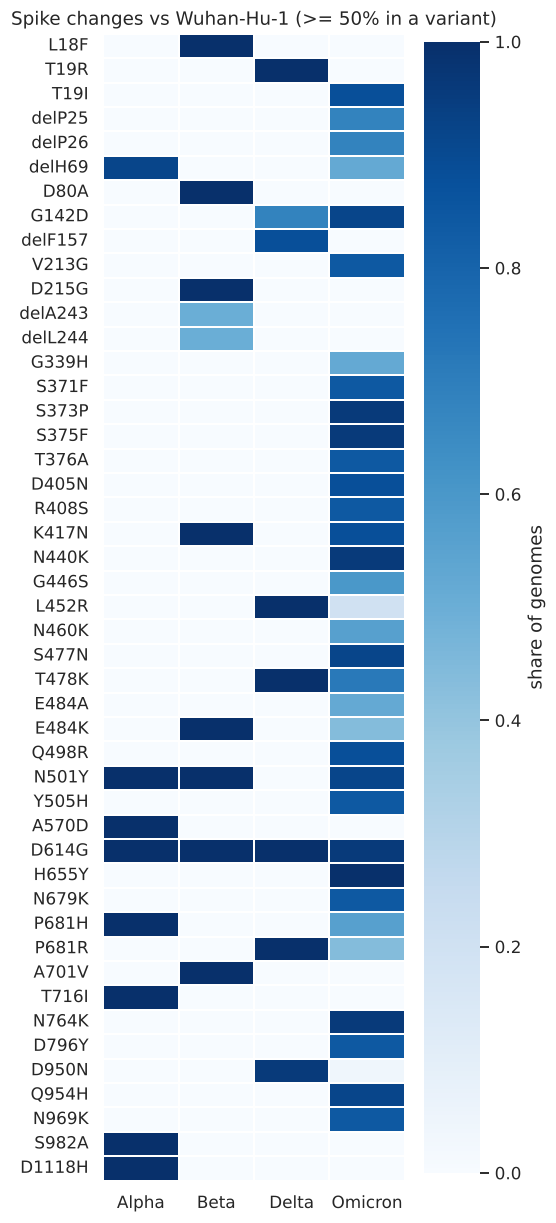

47 Spike changes reach >= 50% in at least one variant


In [ ]:
# ---- Figure 6b: Spike amino-acid changes carried by >= 50% of the genomes of at least one variant ----
ns = events[(events["gene"] == "S") & (events["kind"] != "synonymous")]
freq = (ns.groupby(["label", "variant"]).size().unstack(fill_value=0).reindex(columns=VARIANTS, fill_value=0)
          .div([n_v[v] for v in VARIANTS], axis=1))
top = freq[freq.max(axis=1) >= 0.5]
top = top.assign(pos=[int("".join(ch for ch in s if ch.isdigit())) for s in top.index]).sort_values("pos").drop(columns="pos")
fig, ax = plt.subplots(figsize=(5, max(3, 0.24 * len(top))))
sns.heatmap(top, cmap="Blues", vmin=0, vmax=1, linewidths=0.3, cbar_kws={"label": "share of genomes"}, ax=ax)
ax.set(title="Spike changes vs Wuhan-Hu-1 (>= 50% in a variant)", xlabel="", ylabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6b_spike_mutations.png", bbox_inches="tight"); plt.show()
print(f"{len(top)} Spike changes reach >= 50% in at least one variant")

**Interpretation 5.4 :
The pipeline check passed. D614G is present in 100% of Alpha, Beta and Delta genomes and 96% of Omicron genomes. N501Y is present in Alpha, Beta and 92% of Omicron, but absent from Delta (0/25). E484K is present in all 4 Beta genomes. L452R, T478K and P681R are present in 100% of Delta genomes. RdRp P323L is present in 100% of genomes. Two results need a note. First, E484K appears in 44% of Omicron genomes and E484A in 52%. Second, the variant consensus of Omicron carries 33 Spike substitutions (8.6/kb), against 7 for Alpha, 8 for Beta and 7 for Delta. Across the four variant consensuses, Spike has 53 amino-acid-changing substitutions and 1 synonymous change, and RdRp has 5 and 4. RdRp is the only gene where synonymous changes are nearly as common as amino-acid changes, which fits strong constraint on its protein sequence. This is a simple count ratio, not a formal dN/dS, and the counts are small.

### 5.5 Statistical evidence
**What is being tested.** The hypothesis is that Spike varies more than RdRp, E and M. The unit of observation is a **genome**; for each genome we have one substitution density (differences from Wuhan-Hu-1 per 1,000 compared sites) for each of the five genes. Because the same genomes are measured on all five genes, the data are **paired**, so the tests are:

| Test | Question | Why this test |
|---|---|---|
| **Friedman** | Do the five genes differ in density at all? | Repeated measures, non-parametric (densities are skewed and have many zeros) |
| **Wilcoxon signed-rank**, Holm-corrected, all 10 gene pairs | Which genes differ from which? | Paired post-hoc test; Holm controls the false-positive rate across 10 comparisons |
| **Fisher's exact**, Holm-corrected | Is Spike (and its RBD) richer in variable *sites* than the other genes? | Compares proportions of variable sites between genes |
| **Kruskal-Wallis** per gene | Do the variants differ within a gene? | Four independent groups, non-parametric |
| **Bootstrap 95% CI** (resampling genomes within variant) | How certain are the per-gene estimates of pi and density? | Shows uncertainty, which matters most for the small Beta group |

**Limitation to state in the report:** genomes from the same lineage are not independent (they share ancestry). Stratified sampling reduces this but cannot remove it, so p-values should be read as **descriptive evidence about this sample**, not as formal population inference.

In [ ]:
wide = dens.pivot(index="strain", columns="gene", values="density_per_kb")[GENE_ORDER]
print("Median substitutions per kb vs Wuhan-Hu-1:")
print(wide.median().round(2).to_string(), "\n")

# 1) Friedman test across the five genes (all genomes, then each variant)
rows = [{"group": "All variants", "n_genomes": len(wide), **dict(zip(["chi2", "p_value"], stats.friedmanchisquare(*[wide[g] for g in GENE_ORDER])))}]
for v in VARIANTS:
    w = wide.loc[sel.loc[sel["variant"] == v, "strain"]]
    try:
        chi, p = stats.friedmanchisquare(*[w[g] for g in GENE_ORDER])
    except ValueError:
        chi, p = np.nan, np.nan
    rows.append({"group": v, "n_genomes": len(w), "chi2": chi, "p_value": p})
friedman = pd.DataFrame(rows).set_index("group")
display(friedman.style.format({"chi2": "{:.1f}", "p_value": "{:.2e}"}))
friedman.to_csv(RES_DIR / "stage5_stats_friedman.csv")

Median substitutions per kb vs Wuhan-Hu-1:
gene
S       4.19
E       0.00
M       1.49
N       5.56
RdRp    1.07 



,n_genomes,chi2,p_value
group,,,
All variants,79,202.7,9.82e-43
Alpha,25,94.9,1.18e-19
Beta,4,12.8,1.23e-02
Delta,25,83.3,3.49e-17
Omicron,25,81.0,1.09e-16


In [ ]:
# 2) Pairwise Wilcoxon signed-rank tests with Holm correction
rows = []
for a, b in combinations(GENE_ORDER, 2):
    d = wide[a] - wide[b]
    p = 1.0 if (d == 0).all() else stats.wilcoxon(wide[a], wide[b]).pvalue
    rows.append({"gene_A": a, "gene_B": b, "median_A": wide[a].median(), "median_B": wide[b].median(),
                 "median_diff_(A-B)": d.median(), "p_raw": p})
pw = pd.DataFrame(rows)
pw["p_holm"] = multipletests(pw["p_raw"], method="holm")[1]
pw["significant_(p<0.05)"] = pw["p_holm"] < 0.05
display(pw.style.format({"median_A": "{:.2f}", "median_B": "{:.2f}", "median_diff_(A-B)": "{:.2f}", "p_raw": "{:.2e}", "p_holm": "{:.2e}"}))
pw.to_csv(RES_DIR / "stage5_stats_pairwise_wilcoxon.csv", index=False)

,gene_A,gene_B,median_A,median_B,median_diff_(A-B),p_raw,p_holm,significant_(p<0.05)
0,S,E,4.19,0.00,4.19,1.73e-12,1.21e-11,True
1,S,M,4.19,1.49,4.19,2.46e-14,1.97e-13,True
2,S,N,4.19,5.56,0.13,2.22e-01,2.70e-01,False
3,S,RdRp,4.19,1.07,2.95,1.12e-14,1.10e-13,True
4,E,M,0.00,1.49,-1.49,7.36e-05,2.94e-04,True
5,E,N,0.00,5.56,-3.97,1.82e-11,1.09e-10,True
6,E,RdRp,0.00,1.07,-0.72,1.35e-01,2.70e-01,False
7,M,N,1.49,5.56,-2.47,7.80e-11,3.90e-10,True
8,M,RdRp,1.49,1.07,0.78,1.74e-03,5.21e-03,True
9,N,RdRp,5.56,1.07,3.77,1.10e-14,1.10e-13,True


In [ ]:
# 3) Fisher's exact test on the share of variable sites: Spike vs each other gene, and the RBD vs the rest
var_sites = {g: int((SITE[g]["minor"] >= MIN_MINOR).sum()) for g in GENE_ORDER}
L_ = {g: STATES[g].shape[1] for g in GENE_ORDER}
rbd = slice(3 * (RBD_AA[0] - 1), 3 * RBD_AA[1])
is_var_S = SITE["S"]["minor"] >= MIN_MINOR
v_rbd, n_rbd = int(is_var_S[rbd].sum()), rbd.stop - rbd.start
v_nonrbd, n_nonrbd = var_sites["S"] - v_rbd, L_["S"] - n_rbd
v_oth, n_oth = sum(var_sites[g] for g in GENE_ORDER[1:]), sum(L_[g] for g in GENE_ORDER[1:])

tests = [("Spike vs " + g, var_sites["S"], L_["S"], var_sites[g], L_[g]) for g in GENE_ORDER[1:]]
tests += [("Spike RBD vs rest of Spike", v_rbd, n_rbd, v_nonrbd, n_nonrbd),
          ("Spike RBD vs E+M+N+RdRp pooled", v_rbd, n_rbd, v_oth, n_oth)]
rows = []
for name, va, na, vb, nb in tests:
    odds, p = stats.fisher_exact([[va, na - va], [vb, nb - vb]])
    rows.append({"comparison": name, "variable_A": f"{va}/{na} ({100*va/na:.1f}%)", "variable_B": f"{vb}/{nb} ({100*vb/nb:.1f}%)",
                 "odds_ratio": odds, "p_raw": p})
fisher = pd.DataFrame(rows)
fisher["p_holm"] = multipletests(fisher["p_raw"], method="holm")[1]
display(fisher.style.format({"odds_ratio": "{:.2f}", "p_raw": "{:.2e}", "p_holm": "{:.2e}"}))
fisher.to_csv(RES_DIR / "stage5_stats_fisher.csv", index=False)

# 4) Kruskal-Wallis: do the variants differ within each gene?
rows = []
for g in GENE_ORDER:
    groups = [dens[(dens["gene"] == g) & (dens["variant"] == v)]["density_per_kb"].values for v in VARIANTS]
    H, p = stats.kruskal(*groups)
    rows.append({"gene": g, **{f"median_{v}": np.median(x) for v, x in zip(VARIANTS, groups)}, "H": H, "p_raw": p})
kw = pd.DataFrame(rows).set_index("gene")
kw["p_holm"] = multipletests(kw["p_raw"], method="holm")[1]
display(kw.style.format({"H": "{:.1f}", "p_raw": "{:.2e}", "p_holm": "{:.2e}", **{f"median_{v}": "{:.2f}" for v in VARIANTS}}))
kw.to_csv(RES_DIR / "stage5_stats_kruskal_by_variant.csv")

,comparison,variable_A,variable_B,odds_ratio,p_raw,p_holm
0,Spike vs E,132/3822 (3.5%),4/228 (1.8%),2.00,2.52e-01,2.52e-01
1,Spike vs M,132/3822 (3.5%),12/669 (1.8%),1.96,2.33e-02,5.87e-02
2,Spike vs N,132/3822 (3.5%),27/1260 (2.1%),1.63,1.96e-02,5.87e-02
3,Spike vs RdRp,132/3822 (3.5%),13/2796 (0.5%),7.66,4.72e-19,2.83e-18
4,Spike RBD vs rest of Spike,46/669 (6.9%),86/3153 (2.7%),2.63,1.01e-06,4.06e-06
5,Spike RBD vs E+M+N+RdRp pooled,46/669 (6.9%),56/4953 (1.1%),6.46,2.70e-17,1.35e-16


,median_Alpha,median_Beta,median_Delta,median_Omicron,H,p_raw,p_holm
gene,,,,,,,
S,4.19,3.66,3.66,12.82,53.2,1.68e-11,3.37e-11
E,0.00,6.58,0.00,4.39,61.6,2.63e-13,1.05e-12
M,0.00,0.75,1.49,5.98,69.1,6.70e-15,3.35e-14
N,5.56,0.79,3.17,11.11,55.9,4.34e-12,1.30e-11
RdRp,1.79,0.54,0.72,1.07,44.4,1.24e-09,1.24e-09


In [ ]:
# 5) Bootstrap 95% CIs (resample genomes with replacement inside each variant, 1000 times)
rng = np.random.default_rng(SEED)
by_var = [np.where(var_arr == v)[0] for v in VARIANTS]
boot_rows = []
for g in GENE_ORDER:
    X = STATES[g][1:]
    onehot = (X[..., None] == np.arange(5)).astype(np.int16)        # (n, L, 5)
    dg = wide[g].values
    pis, dns = [], []
    for _ in range(N_BOOT):
        samp = np.concatenate([rng.choice(ix, size=len(ix), replace=True) for ix in by_var])
        c = onehot[samp].sum(axis=0).T                              # (5, L)
        n = c.sum(axis=0); p = c / np.maximum(n, 1)
        pis.append(np.where(n > 1, n / np.maximum(n - 1, 1) * (1 - (p ** 2).sum(axis=0)), 0).mean())
        dns.append(dg[samp].mean())
    boot_rows.append({"gene": g, "pi": SITE[g]["pi"].mean(), "pi_lo": np.percentile(pis, 2.5), "pi_hi": np.percentile(pis, 97.5),
                      "mean_density_per_kb": dg.mean(), "dens_lo": np.percentile(dns, 2.5), "dens_hi": np.percentile(dns, 97.5)})
boot = pd.DataFrame(boot_rows).set_index("gene")
display(boot.round(4))
boot.to_csv(RES_DIR / "stage5_stats_bootstrap_ci.csv")

,pi,pi_lo,pi_hi,mean_density_per_kb,dens_lo,dens_hi
gene,,,,,,
S,0.0103,0.0092,0.0113,7.4701,6.1173,8.8747
E,0.0031,0.0026,0.0038,1.9431,1.3880,2.6094
M,0.0047,0.0042,0.0052,3.0085,2.3651,3.6896
N,0.0079,0.0073,0.0084,6.0896,5.2956,6.9231
RdRp,0.0014,0.0012,0.0015,1.2224,1.1137,1.3265


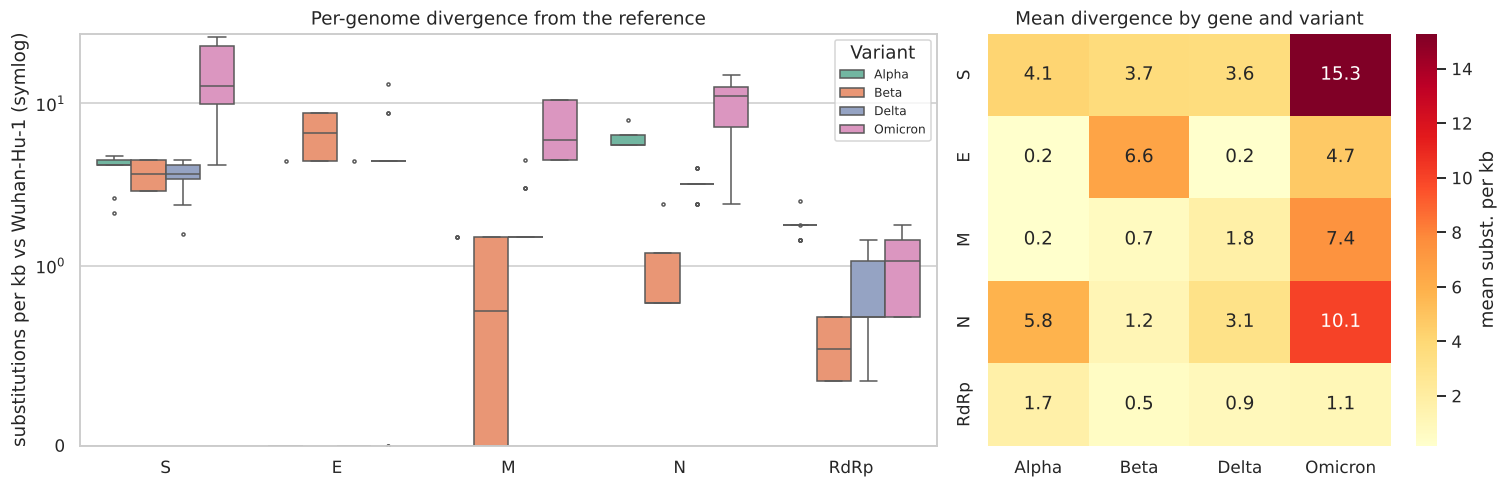

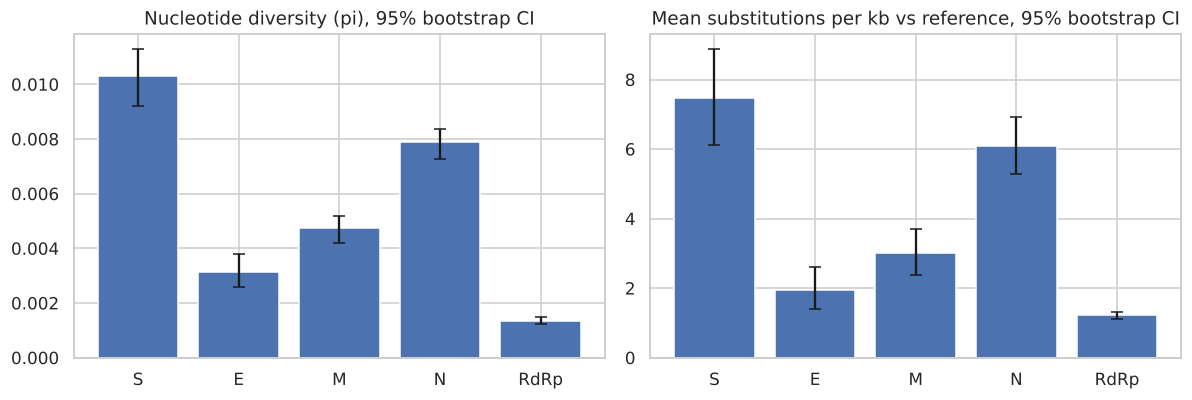

In [ ]:
# ---- Figures 6c-6d ----
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.7, 1]})
sns.boxplot(data=dens, x="gene", y="density_per_kb", hue="variant", hue_order=VARIANTS, fliersize=2, ax=ax[0], palette="Set2")
ax[0].set_yscale("symlog", linthresh=1); ax[0].set_ylim(bottom=0)
ax[0].set(xlabel="", ylabel="substitutions per kb vs Wuhan-Hu-1 (symlog)", title="Per-genome divergence from the reference")
ax[0].legend(title="Variant", fontsize=8)
hm = dens.pivot_table(index="gene", columns="variant", values="density_per_kb", aggfunc="mean", observed=True)[VARIANTS]
sns.heatmap(hm, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "mean subst. per kb"}, ax=ax[1])
ax[1].set(title="Mean divergence by gene and variant", xlabel="", ylabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6c_divergence_by_gene_variant.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, (col, lo, hi, ttl) in zip(ax, [("pi", "pi_lo", "pi_hi", "Nucleotide diversity (pi)"),
                                      ("mean_density_per_kb", "dens_lo", "dens_hi", "Mean substitutions per kb vs reference")]):
    a.bar(boot.index, boot[col], yerr=[boot[col] - boot[lo], boot[hi] - boot[col]], color="#4C72B0", capsize=4)
    a.set(title=ttl + ", 95% bootstrap CI")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6d_bootstrap_ci.png", bbox_inches="tight"); plt.show()

**Interpretation 5.5 :**
The Friedman test shows that the five genes differ in divergence from the reference (χ² = 202.7, n = 79, p ≈ 10⁻⁴²), and the result is the same inside each variant. After Holm correction, Spike has a higher median divergence than E, M and RdRp (adjusted p ≤ 10⁻¹¹), but not than N (adjusted p = 0.27). N has the highest median (5.56 per kb, against 4.19 for Spike), so N is as variable as Spike in this sample, which the hypothesis did not predict. At site level, Spike has more variable sites than RdRp (odds ratio 7.7, adjusted p < 10⁻¹⁷). Against E, M and N the difference is not significant after correction (adjusted p = 0.25, 0.059 and 0.059). The RBD is richer in variable sites than the rest of Spike (6.9% against 2.7%, odds ratio 2.6, adjusted p < 0.001) and than the other four genes pooled (1.1%). The variants differ within every gene (Kruskal-Wallis, all adjusted p < 10⁻⁹), and Omicron has the highest medians in S, N and M. The bootstrap 95% intervals for π do not overlap between any two genes, so the order S > N > M > E > RdRp is reliable for this sample. The intervals for mean divergence overlap for S and N, and for M and E. The Beta results rest on 4 genomes and should not be interpreted alone. The main limit is that genomes of the same lineage are related, so the p-values describe this sample and not the virus population.

---
## Summary and hand-off
- **Alignment:** five genes aligned with MAFFT (files in `results/alignments/`).
- **Conservation:** per-site entropy, per-gene variable-site rates, nucleotide diversity, identity to Wuhan-Hu-1 (`results/stage5_gene_conservation.csv`, `stage5_genome_identity.csv`).
- **Mutation table:** gene x variant (`stage5_mutation_table.csv`), known-mutation check (`stage5_known_mutations.csv`), every codon change per genome (`stage5_codon_changes_per_genome.csv`).
- **Statistics:** Friedman, Wilcoxon (Holm), Fisher, Kruskal-Wallis and bootstrap CIs (`results/stage5_stats_*.csv`).
- **For Stage 6 (Myra):** `stage5_codon_changes_per_genome.csv` has the amino-acid changes to place on protein domains and compare with the literature.
- **For Stage 7 (Alvin):** the 5.1 sample is deliberately small and balanced; the classifier should split train / test by **lineage**, not randomly, to avoid near-duplicate leakage.